# GLANCE: Cross-dataset integration of single-cell proteomics

This tutorial demonstrates **cross-dataset integration** of single-cell mass spectrometry proteomics data with GLANCE, followed by UMAP visualization before and after integration.

The processed data and annotations are available from the Slavov Lab:

- [Leduc et al. dataset](https://scp.slavovlab.net/Leduc_et_al_2022)
- [Derks et al. dataset](https://scp.slavovlab.net/Derks_et_al_2022)

**References:**

- Leduc A, Huffman RG, Cantlon J, Khan S, Slavov N. *Exploring functional protein covariation across single cells using nPOP*. *Genome Biology* **23**, 261 (2022). [doi:10.1186/s13059-022-02817-5](https://doi.org/10.1186/s13059-022-02817-5).
- Derks J, Leduc A, Wallmann G, et al. *Increasing the throughput of sensitive proteomics by plexDIA*. *Nature Biotechnology* (2022). [doi:10.1038/s41587-022-01389-w](https://doi.org/10.1038/s41587-022-01389-w).

## 1. Setup

The example uses `glancevae`, `scanpy`, `anndata`, `pandas`, and PyTorch. PyTorch runs on a CUDA GPU when available and otherwise uses the CPU.

In [1]:
import warnings
from tqdm.std import TqdmWarning

# Silence an optional Jupyter progress-bar warning.
warnings.filterwarnings(
    "ignore",
    message=r"IProgress not found.*",
    category=TqdmWarning,
)

import pandas as pd
import torch
import scanpy as sc
import anndata as ad

from pathlib import Path
from glancevae import seed_everything, GLANCE

SEED = 2026
seed_everything(SEED)
sc.settings.seed = SEED

Global seed set to 2026 (deterministic=True)


## 2. Load and preprocess data

Place the downloaded files in `./data/Leduc2022/` and `./data/Derks2023/`, as specified below. Each abundance matrix is transposed into **cells × proteins** orientation.

The datasets use different cell-type labels and batch annotations. These are harmonized before concatenation; only proteins shared by both datasets are retained (`join="inner"`).

In [2]:
# Leduc2022 files
DATASET1_PATH = Path("./data/Leduc2022/")
SC_MATRIX1_PATH = DATASET1_PATH / "t6.csv"
META1_PATH = DATASET1_PATH / "meta.csv"

# Derks2023 files
DATASET2_PATH = Path("./data/Derks2023/")
SC_MATRIX2_PATH = DATASET2_PATH / "Proteins_SC_IDs.txt"
META2_PATH = DATASET2_PATH / "Meta_SingleCell_updated_1.tsv"

### Leduc2022

Read the abundance matrix and metadata, and harmonize the cell-type labels. Batch IDs retain their Leduc2022-specific prefix.

In [3]:
raw_df1 = pd.read_csv(SC_MATRIX1_PATH, index_col=0)
metadata_df1 = pd.read_csv(META1_PATH, index_col="id")

abundance_df1 = raw_df1.T
cell_ids1 = abundance_df1.index

cell_type_map1 = {
    cid: ("Melanoma" if value == "m" else "Monocyte")
    for cid, value in metadata_df1["celltype"].items()
}
batch_map1 = {
    cid: f"Leduc2022_{value}"
    for cid, value in metadata_df1["lcbatch"].items()
}

obs1 = pd.DataFrame(
    {
        "cell_type": [cell_type_map1[cid] for cid in cell_ids1],
        "batch": [batch_map1[cid] for cid in cell_ids1],
    },
    index=cell_ids1,
)
var1 = pd.DataFrame(index=abundance_df1.columns)

adata1 = ad.AnnData(X=abundance_df1.values, obs=obs1, var=var1)

### Derks2023

Read the second dataset and harmonize its cell-type labels. The original analysis treats these cells as a single batch (`Derks2023`).

In [4]:
raw_df2 = pd.read_csv(SC_MATRIX2_PATH, index_col=0, delimiter="\t")
metadata_df2 = pd.read_csv(META2_PATH, index_col="id", delimiter="\t")

abundance_df2 = raw_df2.T
cell_ids2 = abundance_df2.index

cell_type_map2 = {
    cid: ("Monocyte" if value[:5] == "U-937" else value)
    for cid, value in metadata_df2["Celltype"].items()
}

obs2 = pd.DataFrame(
    {
        "cell_type": [
            cell_type_map2[cid].replace("_t", "").replace("_DB", "")
            for cid in cell_ids2
        ],
        "batch": ["Derks2023"] * len(cell_ids2),
    },
    index=cell_ids2,
)
var2 = pd.DataFrame(index=abundance_df2.columns)

adata2 = ad.AnnData(X=abundance_df2.values, obs=obs2, var=var2)

### Combine datasets

Concatenate both datasets using their shared proteins, add a `source` annotation, and scale the abundance matrix.

In [5]:
adata = ad.concat(
    [adata1, adata2],
    axis=0,
    join="inner",
    label="source",
    keys=["Leduc2022", "Derks2023"],
    index_unique="-",
)

sc.pp.scale(adata, max_value=10)

### Input abundance visualization

UMAP of the scaled input abundance matrix (`adata.X`), colored by cell type, batch, and dataset source.

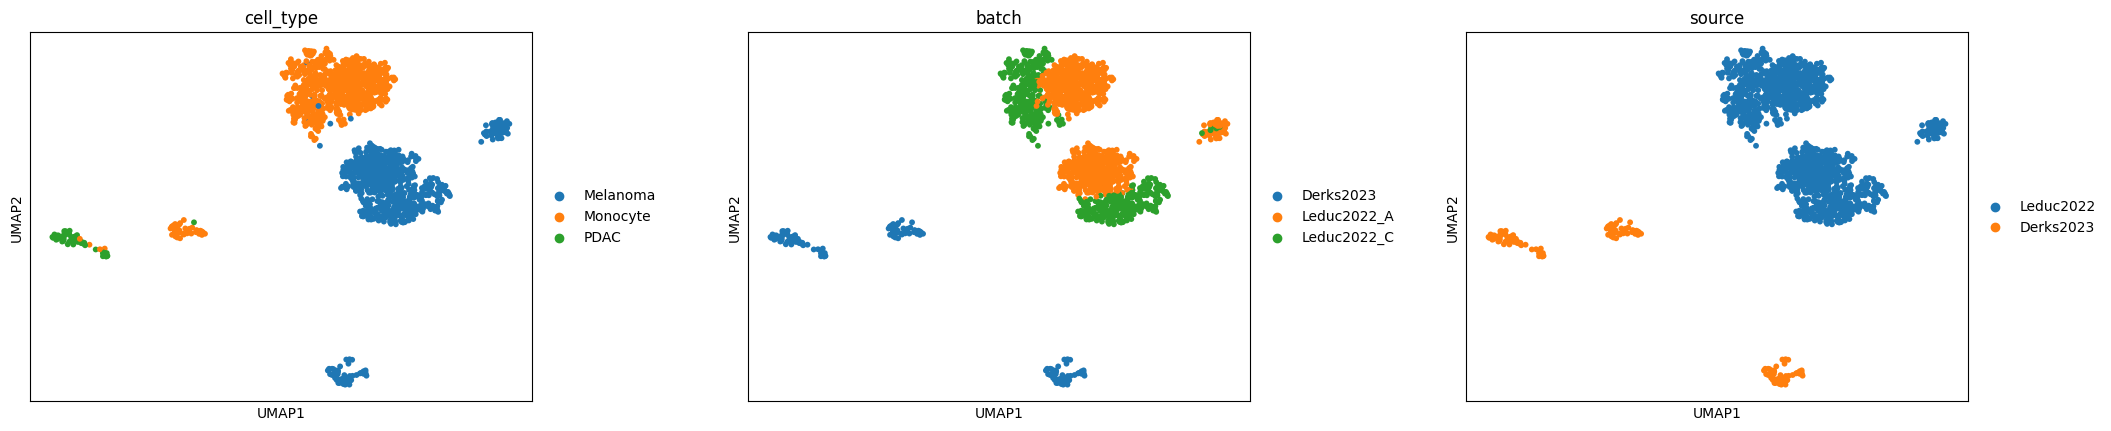

In [6]:
sc.pp.neighbors(adata, use_rep="X")
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color=["cell_type", "batch", "source"],
    wspace=0.3,
)

## 3. Integrate cells with GLANCE

Fit GLANCE using the `batch` annotation. The integrated representation is stored in `adata.obsm["GLANCE"]`.

In [7]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = GLANCE(adata=adata, label_col="batch", random_state=SEED, device=device)

model.prepare_local_manifold()
model.prepare_geom_refinement()
model.fit_transform()

[GLANCE] Local manifold graph built | cells=1707, batches=3, k_pos=10, n_neg=20, far_quantile=0.70 | pos_edges=17070, neg_edges=34140
[GLANCE] Geometric refinement registered | start_epoch=2000, k_pos=10, n_neg=20, far_quantile=0.95, mutual=True, rebuild_every=None


[GLANCE] Ensemble: 1/3: 100%|█████| 2500/2500 [00:29<00:00, 83.98it/s]


[GLANCE] Training complete | Geometric edges: pos_edges=9886, neg_edges=34140
[GLANCE] Same-batch pos-edge fraction: 0.867 (random baseline: 0.333)


[GLANCE] Ensemble: 2/3: 100%|█████| 2500/2500 [00:30<00:00, 81.62it/s]


[GLANCE] Training complete | Geometric edges: pos_edges=9608, neg_edges=34140
[GLANCE] Same-batch pos-edge fraction: 0.832 (random baseline: 0.333)


[GLANCE] Ensemble: 3/3: 100%|█████| 2500/2500 [00:29<00:00, 83.94it/s]

[GLANCE] Training complete | Geometric edges: pos_edges=9886, neg_edges=34140
[GLANCE] Same-batch pos-edge fraction: 0.839 (random baseline: 0.333)


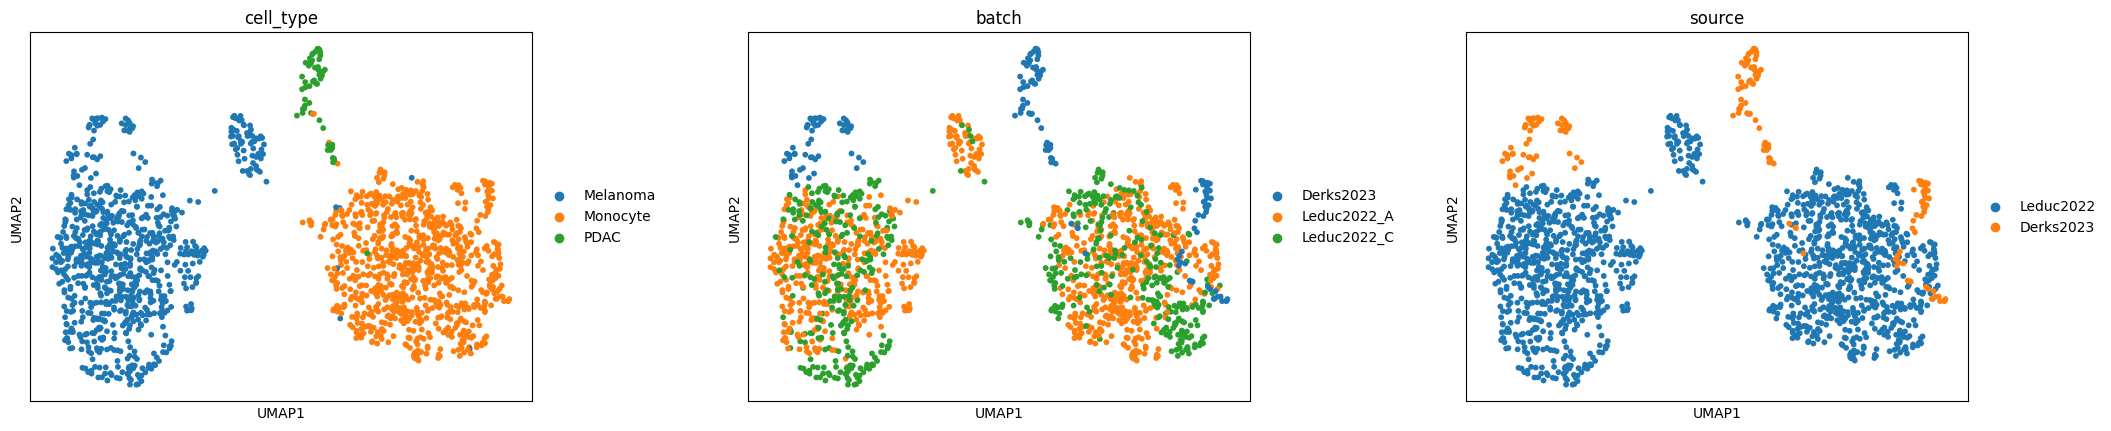

In [8]:
sc.pp.neighbors(adata, use_rep="GLANCE")
sc.tl.umap(adata)
sc.pl.umap(
    adata,
    color=["cell_type", "batch", "source"],
    wspace=0.3,
)